In [1]:
# installs
!pip install triton==3.2.0
# triton 3.3 and later does not support T4 GPU well

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.2/253.2 MB 6.2 MB/s eta 0:00:00
  Attempting uninstall: triton
    Found existing installation: triton 3.6.0
    Uninstalling triton-3.6.0:
      Successfully uninstalled triton-3.6.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu130 requires triton==3.6.0; platform_system == "Linux", but you have triton 3.2.0 which is incompatible.


In [2]:
# imports
import torch
import torch.nn.functional as F
import torch._functorch.config
torch._functorch.config.donated_buffer = False

import triton
import triton.language as tl

import os

In [3]:
#@title torch SwiGLU
def check_swiglu(x, Wg, Wu, Wd):
  x, Wg, Wu, Wd = x.float(), Wg.float(), Wu.float(), Wd.float()
  return ((F.silu(x @ Wg)) * (x @ Wu)) @ Wd

def eager_swiglu(x, Wg, Wu, Wd):
  return ((F.silu(x @ Wg)) * (x @ Wu)) @ Wd

compiled_swiglu = torch.compile(eager_swiglu)

In [4]:
#@title fwd1
# Forward Kernel 1:
# Calculate elementwise product of activated gated projection * up projection
@triton.jit
def fwd1_kernel(
    x_ptr, # input, M x N
    gate_ptr, # gate matrix, N x K
    up_ptr, # up matrix, N x K
    M, N, K, # N is the hidden dimension
    h_ptr, # elementwise product of activated a * b
    stride_xm, stride_xn,
    stride_gate_n, stride_gate_k,
    stride_up_n, stride_up_k,
    stride_hm, stride_hk,
    BLOCK_SIZE_M: tl.constexpr,
    BLOCK_SIZE_N: tl.constexpr,
    BLOCK_SIZE_K: tl.constexpr,
    GROUP_SIZE_M: tl.constexpr,
    WRITE_AB: tl.constexpr, # boolean that's true or false
    a_ptr=None, # write gate proj (pre-activation), M x K
    b_ptr=None, # write up proj, M x K
    stride_am=0, stride_ak=0,
    stride_bm=0, stride_bk=0,

):
  # first calculate the M x K tile of a/b/y that we are calculating (pid_m and pid_n)
  pid = tl.program_id(0)
  num_programs_m = tl.cdiv(M, BLOCK_SIZE_M)
  num_programs_k = tl.cdiv(K, BLOCK_SIZE_K)
  programs_per_group = GROUP_SIZE_M * num_programs_k
  group_id = pid // programs_per_group
  group_start_m = group_id * GROUP_SIZE_M
  group_size_m = min(GROUP_SIZE_M, num_programs_m - group_start_m)
  pid_m = group_start_m + ((pid % programs_per_group) % group_size_m)
  pid_k = (pid % programs_per_group) // group_size_m

  # calculate value for the tile (basically a standard matmul)
  # pid_m, pid_k :
  # Rows: pid_m * BLOCK_SIZE_M + [0, BLOCK_SIZE_M]
  # Col: pid_k * BLOCK_SIZE_K + [0, BLOCK_SIZE_K]
  acc_a = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_K), tl.float32)
  acc_b = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_K), tl.float32)
  offs_m = pid_m * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)
  offs_k = pid_k * BLOCK_SIZE_K + tl.arange(0, BLOCK_SIZE_K)
  offsets_m = offs_m % M # modulo trick
  offsets_k = offs_k % K # modulo trick
  # offsets_n is created on the fly in the for-loop
  for n in range(0, N, BLOCK_SIZE_N): # N is the hidden dimension for the first matmul
    offsets_n = n + tl.arange(0, BLOCK_SIZE_N)
    x = tl.load(x_ptr + offsets_m[:, None] * stride_xm + offsets_n[None, :] * stride_xn,
                mask = offsets_n[None, :] < N,
                other = 0.0)
    gate = tl.load(gate_ptr + offsets_n[:, None] * stride_gate_n + offsets_k[None, :] * stride_gate_k,
                   mask = offsets_n[:, None] < N,
                   other = 0.0)
    up = tl.load(up_ptr + offsets_n[:, None] * stride_up_n + offsets_k[None, :] * stride_up_k,
                 mask = offsets_n[:, None] < N,
                 other = 0.0)
    acc_a = tl.dot(x, gate, acc_a)
    acc_b = tl.dot(x, up, acc_b)

  if(WRITE_AB):
    tl.store(a_ptr + offsets_m[:, None]*stride_am + offsets_k[None, :]*stride_ak,
             acc_a,
             mask = (offs_m[:, None] < M) & (offs_k[None, :] < K))
    tl.store(b_ptr + offsets_m[:, None]*stride_bm + offsets_k[None, :]*stride_bk,
             acc_b,
             mask = (offs_m[:, None] < M) & (offs_k[None, :] < K))

  tl.store(h_ptr + offsets_m[:, None] * stride_hm + offsets_k[None, :]*stride_hk,
           tl.sigmoid(acc_a) * acc_a * acc_b,
           mask = (offs_m[:, None] < M) & (offs_k[None, :] < K))

In [5]:
#@title fwd2 / bwd2
# Generic matmul kernel with stride support

@triton.jit
def matmul_kernel(
    a_ptr, # M x K
    b_ptr, # K x N
    y_ptr, # M x N
    M, N, K, # K is the hidden dimension
    stride_am, stride_ak,
    stride_bk, stride_bn,
    stride_ym, stride_yn,
    BLOCK_SIZE_M: tl.constexpr,
    BLOCK_SIZE_N: tl.constexpr,
    BLOCK_SIZE_K: tl.constexpr,
    GROUP_SIZE_M: tl.constexpr,
):
  pid = tl.program_id(0)
  num_programs_m = tl.cdiv(M, BLOCK_SIZE_M)
  num_programs_n = tl.cdiv(N, BLOCK_SIZE_N)
  programs_per_group = GROUP_SIZE_M * num_programs_n
  group_id = pid // programs_per_group
  first_id_m = group_id * GROUP_SIZE_M
  group_size_m = min(num_programs_m - first_id_m, GROUP_SIZE_M)
  pid_m = first_id_m + ((pid % programs_per_group) % group_size_m)
  pid_n = (pid % programs_per_group) // group_size_m

  offs_m = (pid_m * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M))
  offs_n = (pid_n * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N))
  offsets_m = offs_m % M # modulo trick
  offsets_n = offs_n % N # modulo trick
  acc = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_N), tl.float32)
  for k in range(0, K, BLOCK_SIZE_K):
    offsets_k = k + tl.arange(0, BLOCK_SIZE_K)
    a = tl.load(a_ptr + offsets_m[:, None] * stride_am + offsets_k[None, :] * stride_ak,
                mask = offsets_k[None, :] < K,
                other = 0.0)
    b = tl.load(b_ptr + offsets_k[:, None] * stride_bk + offsets_n[None, :] * stride_bn,
                mask = offsets_k[:, None] < K,
                other = 0.0)
    acc = tl.dot(a, b, acc)
  tl.store(y_ptr + offsets_m[:, None] * stride_ym + offsets_n[None, :] * stride_yn,
           acc,
           mask = (offs_m[:, None] < M) & (offs_n[None, :] < N))


In [6]:
#@title bwd_1
# Backward Kernel 1:
# Compute dh (matmul) tile-by-tile, then write da and db in the epilogue.
# Note: No need to write dh to memory
# dh = dy @ (W_d)^T
# da = dh * b * s * (1 + a*(1 - s)), where s = sigmoid(a)
# db = dh * silu(a)
@triton.jit
def bwd1_kernel(
    dy_ptr, # M x N
    Wd_ptr, # K x N; transpose is N x K
    a_ptr, # M x K
    b_ptr, # M x K
    da_ptr, # M x K
    db_ptr, # M x K
    M, N, K, # hidden dimension is N
    stride_dym, stride_dyn,
    stride_Wdk, stride_Wdn,
    stride_dam, stride_dak,
    stride_dbm, stride_dbk,
    stride_am, stride_ak,
    stride_bm, stride_bk,
    BLOCK_SIZE_M: tl.constexpr,
    BLOCK_SIZE_N: tl.constexpr,
    BLOCK_SIZE_K: tl.constexpr,
    GROUP_SIZE_M: tl.constexpr,
):
  pid = tl.program_id(0)
  num_programs_m = tl.cdiv(M, BLOCK_SIZE_M)
  num_programs_k = tl.cdiv(K, BLOCK_SIZE_K)
  programs_per_group = num_programs_k * GROUP_SIZE_M
  group_id = pid // programs_per_group
  first_id_m = group_id * GROUP_SIZE_M
  group_size_m = min(num_programs_m - first_id_m, GROUP_SIZE_M)
  pid_m = first_id_m + (pid % programs_per_group) % group_size_m
  pid_k = (pid % programs_per_group) // group_size_m

  offs_m = pid_m * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)
  offs_k = pid_k * BLOCK_SIZE_K + tl.arange(0, BLOCK_SIZE_K)
  offsets_m = offs_m % M
  offsets_k = offs_k % K

  # dh = dy @ (W_d)^T
  acc_dh = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_K), tl.float32)
  for n in range(0, N, BLOCK_SIZE_N):
    offsets_n = n + tl.arange(0, BLOCK_SIZE_N)
    dy = tl.load(dy_ptr + offsets_m[:, None] * stride_dym + offsets_n[None, :] * stride_dyn,
                 mask = offsets_n[None, :] < N,
                 other = 0.0)
    WdT = tl.load(Wd_ptr + offsets_k[None, :]*stride_Wdk + offsets_n[:, None]*stride_Wdn,
                  mask = offsets_n[:, None] < N,
                  other = 0.0)
    acc_dh = tl.dot(dy, WdT, acc_dh)
  # Calculate da and db in the epilogue so we don't have to read and write dh repetitively
  # da = dh * b * s * (1 + a*(1 - s)), where s = sigmoid(a)
  # db = dh * silu(a)
  a = tl.load(a_ptr + offsets_m[:, None]*stride_am + offsets_k[None, :]*stride_ak).to(tl.float32)
  b = tl.load(b_ptr + offsets_m[:, None]*stride_bm + offsets_k[None, :]*stride_bk).to(tl.float32)
  # No need for mask because it wraps around, and elementwise doesn't matter if it loads garbage
  s = tl.sigmoid(a)
  da = acc_dh * b * s * (1 + a*(1 - s))
  db = acc_dh * a * s
  tl.store(da_ptr + offsets_m[:, None]*stride_dam + offsets_k[None, :]*stride_dak,
           da,
           mask = (offs_m[:, None] < M) & (offs_k[None, :] < K))
  tl.store(db_ptr + offsets_m[:, None]*stride_dbm + offsets_k[None, :]*stride_dbk,
           db,
           mask = (offs_m[:, None] < M) & (offs_k[None, :] < K))

In [7]:
#@title bwd_3
# Backward Kernel 3:
# Compute dW_g and dW_u (matmuls)
# dW_g = x^T @ da
# dW_u = x^T @ db

@triton.jit
def bwd3_kernel(
    x_ptr, # M x N; x^T is N x M
    da_ptr, # M x K
    db_ptr, # M x K
    M, N, K, # M is the hidden dimension
    dWg_ptr, # N x K
    dWu_ptr, # N x K
    stride_xm, stride_xn,
    stride_dam, stride_dak,
    stride_dbm, stride_dbk,
    stride_Wgn, stride_Wgk,
    stride_Wun, stride_Wuk,
    BLOCK_SIZE_M: tl.constexpr,
    BLOCK_SIZE_N: tl.constexpr,
    BLOCK_SIZE_K: tl.constexpr,
    GROUP_SIZE_N: tl.constexpr,
):
  pid = tl.program_id(0)
  num_programs_n = tl.cdiv(N, BLOCK_SIZE_N)
  num_programs_k = tl.cdiv(K, BLOCK_SIZE_K)
  programs_per_group = GROUP_SIZE_N * num_programs_k
  group_id = pid // programs_per_group
  first_id_n = group_id * GROUP_SIZE_N
  group_size_n = min(GROUP_SIZE_N, num_programs_n - first_id_n)
  pid_n = first_id_n + (pid % programs_per_group) % group_size_n
  pid_k = (pid % programs_per_group) // group_size_n

  offs_n = pid_n * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)
  offs_k = pid_k * BLOCK_SIZE_K + tl.arange(0, BLOCK_SIZE_K)
  offsets_n = offs_n % N # mod trick
  offsets_k = offs_k % K # mod trick

  # dW_g = x^T @ da
  # dW_u = x^T @ db
  acc_Wg = tl.zeros((BLOCK_SIZE_N, BLOCK_SIZE_K), tl.float32)
  acc_Wu = tl.zeros((BLOCK_SIZE_N, BLOCK_SIZE_K), tl.float32) # N x K -> use BLOCK_SIZE_N x BLOCK_SIZE_K
  for m in range(0, M, BLOCK_SIZE_M):
    offsets_m = m + tl.arange(0, BLOCK_SIZE_M)
    xT = tl.load(x_ptr + offsets_m[None, :]*stride_xm + offsets_n[:, None]*stride_xn,
                 mask = offsets_m[None, :] < M,
                 other = 0.0)
    da = tl.load(da_ptr + offsets_m[:, None] * stride_dam + offsets_k[None, :]*stride_dak,
                 mask = offsets_m[:, None] < M,
                 other = 0.0)
    db = tl.load(db_ptr + offsets_m[:, None] * stride_dbm + offsets_k[None, :]*stride_dbk,
                 mask = offsets_m[:, None] < M,
                 other = 0.0)
    acc_Wg = tl.dot(xT, da, acc_Wg)
    acc_Wu = tl.dot(xT, db, acc_Wu)
  tl.store(dWg_ptr + offsets_n[:, None]*stride_Wgn + offsets_k[None, :]*stride_Wgk,
           acc_Wg,
           mask = (offs_n[:, None]<N) & (offs_k[None, :]<K))
  tl.store(dWu_ptr + offsets_n[:, None]*stride_Wun + offsets_k[None, :]*stride_Wuk,
           acc_Wu,
           mask = (offs_n[:, None]<N) & (offs_k[None, :]<K))

In [8]:
#@title bwd_4
# Backward Kernel 4:
# Compute dx
# dx = da @ W_g^T + db @ W_u^T
@triton.jit
def bwd4_kernel(
    da_ptr, # M x K
    db_ptr, # M x K
    Wg_ptr, # N x K; transpose is K x N
    Wu_ptr, # N x K; transpose is K x N
    dx_ptr, # M x N
    M, N, K, # K is hidden dimension
    stride_dam, stride_dak,
    stride_dbm, stride_dbk,
    stride_Wgn, stride_Wgk,
    stride_Wun, stride_Wuk,
    stride_dxm, stride_dxn,
    BLOCK_SIZE_M: tl.constexpr,
    BLOCK_SIZE_N: tl.constexpr,
    BLOCK_SIZE_K: tl.constexpr,
    GROUP_SIZE_M: tl.constexpr,
):
  pid = tl.program_id(0)
  num_programs_m = tl.cdiv(M, BLOCK_SIZE_M)
  num_programs_n = tl.cdiv(N, BLOCK_SIZE_N)
  programs_per_group = GROUP_SIZE_M * num_programs_n
  group_id = pid // programs_per_group
  first_id_m = group_id * GROUP_SIZE_M
  group_size_m = min(GROUP_SIZE_M, num_programs_m - first_id_m)
  pid_m = first_id_m + (pid % programs_per_group) % group_size_m
  pid_n = (pid % programs_per_group) // group_size_m

  offs_m = pid_m * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)
  offs_n = pid_n * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)
  offsets_m = offs_m % M # modulo trick
  offsets_n = offs_n % N # modulo trick

  # dx = da @ W_g^T + db @ W_u^T
  acc = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_N), tl.float32)
  for k in range(0, K, BLOCK_SIZE_K):
    offsets_k = k + tl.arange(0, BLOCK_SIZE_K)
    da = tl.load(da_ptr + offsets_m[:, None] * stride_dam + offsets_k[None, :]*stride_dak,
                 mask = offsets_k[None, :] < K,
                 other = 0.0)
    db = tl.load(db_ptr + offsets_m[:, None] * stride_dbm + offsets_k[None, :]*stride_dbk,
                 mask = offsets_k[None, :] < K,
                 other = 0.0)
    WgT = tl.load(Wg_ptr + offsets_n[None, :] * stride_Wgn + offsets_k[:, None]*stride_Wgk,
                  mask = offsets_k[:, None] < K,
                  other = 0.0) # masking is always for hidden dimension, because that prevents contaminating the sums
    WuT = tl.load(Wu_ptr + offsets_n[None, :] * stride_Wun + offsets_k[:, None]*stride_Wuk,
                  mask = offsets_k[:, None] < K,
                  other = 0.0)
    acc = tl.dot(da, WgT, acc)
    acc = tl.dot(db, WuT, acc)
  tl.store(dx_ptr + offsets_m[:, None]*stride_dxm + offsets_n[None, :]*stride_dxn,
           acc,
           mask = (offs_m[:, None] < M) & (offs_n[None, :] < N))

In [9]:
#@title SwiGLU Function
# wrap kernels
class SwiGLU(torch.autograd.Function):
  @staticmethod
  def forward(ctx, x, Wg, Wu, Wd):
    M, N = x.shape # x has shape (M, N)
    K = Wg.shape[1] # Wg has shape (N, K)
    # allocate output
    h = torch.empty((M, K), dtype=x.dtype, device=x.device)
    # launch grid size for fwd1_kernel: number of tiles in M x K.
    grid_mk = lambda meta: (triton.cdiv(M, meta['BLOCK_SIZE_M']) * triton.cdiv(K, meta['BLOCK_SIZE_K']), )
    fwd1_kernel[grid_mk](
        x, Wg, Wu,
        M, N, K,
        h, # omit a, b
        x.stride(0), x.stride(1),
        Wg.stride(0),  Wg.stride(1),
        Wu.stride(0), Wu.stride(1),
        # omit stride_am, stride_bm
        h.stride(0), h.stride(1),
        BLOCK_SIZE_M = 128,
        BLOCK_SIZE_N = 16,
        BLOCK_SIZE_K = 64,
        GROUP_SIZE_M = 4,
        WRITE_AB = False,
        num_warps = 4,
        num_stages = 4,
    )
    # h has size (M, K)
    # Wd has size (K, N)
    y = torch.empty((M, N), dtype=x.dtype, device=x.device) # x.dtype probably float16
    grid_mn = lambda meta: (triton.cdiv(M, meta['BLOCK_SIZE_M']) * triton.cdiv(N, meta['BLOCK_SIZE_N']), )
    matmul_kernel[grid_mn](
        h, Wd, y,
        M, N, K,
        h.stride(0), h.stride(1),
        Wd.stride(0), Wd.stride(1),
        y.stride(0), y.stride(1),
        BLOCK_SIZE_M = 128,
        BLOCK_SIZE_N = 128,
        BLOCK_SIZE_K = 16,
        GROUP_SIZE_M = 4,
        num_warps = 4,
        num_stages = 4,
    )
    ctx.save_for_backward(x, Wg, Wu, Wd)
    return y

  @staticmethod
  def backward(ctx, dy):
    x, Wg, Wu, Wd = ctx.saved_tensors
    M, N = x.shape
    K = Wg.shape[1]

    # recalculate a, b, h using forward kernel 1
    # writing h: cost 1 extra write, saves an extra read and another custom matmul kernel on bwd2
    a = torch.empty((M, K), dtype=x.dtype, device=x.device)
    b = torch.empty((M, K), dtype=x.dtype, device=x.device)
    h = torch.empty((M, K), dtype=x.dtype, device=x.device)
    grid_mk = lambda meta: (triton.cdiv(M, meta['BLOCK_SIZE_M']) * triton.cdiv(K, meta['BLOCK_SIZE_K']), )
    fwd1_kernel[grid_mk](
        x, Wg, Wu,
        M, N, K, h,
        x.stride(0), x.stride(1),
        Wg.stride(0), Wg.stride(1),
        Wu.stride(0), Wu.stride(1),
        h.stride(0), h.stride(1),
        BLOCK_SIZE_M = 128,
        BLOCK_SIZE_N = 64,
        BLOCK_SIZE_K = 64,
        GROUP_SIZE_M = 8,
        WRITE_AB = True,
        a_ptr = a, b_ptr = b,
        stride_am = a.stride(0), stride_ak = a.stride(1),
        stride_bm = b.stride(0), stride_bk = b.stride(1),
        num_warps = 4,
        num_stages = 2,
    )

    # allocate output
    da = torch.empty((M, K), dtype=a.dtype, device=x.device)
    db = torch.empty((M, K), dtype=b.dtype, device=x.device)
    # run bwd1 kernel
    bwd1_kernel[grid_mk](
        dy, Wd, a, b, da, db,
        M, N, K,
        dy.stride(0), dy.stride(1),
        Wd.stride(0), Wd.stride(1),
        da.stride(0), da.stride(1),
        db.stride(0), db.stride(1),
        a.stride(0), a.stride(1),
        b.stride(0), b.stride(1),
        BLOCK_SIZE_M = 64,
        BLOCK_SIZE_N = 64,
        BLOCK_SIZE_K = 128,
        GROUP_SIZE_M = 8,
        num_warps = 4,
        num_stages = 2,
    )

    # dW_d = h^T @ dy
    # run bwd2 kernel with grid_kn_mm
    grid_kn_mm = lambda meta: (triton.cdiv(K, meta['BLOCK_SIZE_M'])*triton.cdiv(N, meta['BLOCK_SIZE_N']), )
    # transpose means we need to take K / meta['BLOCK_SIZE_M'] instead of BLOCK_SIZE_K
    dWd = torch.empty((K, N), dtype=Wd.dtype, device=x.device)
    matmul_kernel[grid_kn_mm](
        h, dy, dWd,
        K, N, M,
        h.stride(1), h.stride(0), # swapping the strides makes it see h as its transpose
        dy.stride(0), dy.stride(1),
        dWd.stride(0), dWd.stride(1),
        BLOCK_SIZE_M = 128, # (K, N, M) global shape = (M, N, K) local shape
        BLOCK_SIZE_N = 128,
        BLOCK_SIZE_K = 16,
        GROUP_SIZE_M = 4,
        num_warps = 4,
        num_stages = 4,
    )

    # bwd3 kernel
    dWg = torch.empty((N, K), dtype=Wg.dtype, device=x.device)
    dWu = torch.empty((N, K), dtype=Wu.dtype, device=x.device)

    grid_kn = lambda meta: (triton.cdiv(K, meta['BLOCK_SIZE_K'])*triton.cdiv(N, meta['BLOCK_SIZE_N']), )
    bwd3_kernel[grid_kn](
        x, da, db,
        M, N, K,
        dWg, dWu,
        x.stride(0), x.stride(1),
        da.stride(0), da.stride(1),
        db.stride(0), db.stride(1),
        dWg.stride(0), dWg.stride(1),
        dWu.stride(0), dWu.stride(1),
        BLOCK_SIZE_M = 32,
        BLOCK_SIZE_N = 128,
        BLOCK_SIZE_K = 64,
        GROUP_SIZE_N = 8,
        num_warps = 4,
        num_stages = 4,
    )

    # bwd4 kernel
    grid_mn = lambda meta: (triton.cdiv(M, meta['BLOCK_SIZE_M'])*triton.cdiv(N, meta['BLOCK_SIZE_N']), )
    dx = torch.empty((M, N), dtype=x.dtype, device=x.device)
    bwd4_kernel[grid_mn](
        da, db, Wg, Wu, dx,
        M, N, K,
        da.stride(0), da.stride(1),
        db.stride(0), db.stride(1),
        Wg.stride(0), Wg.stride(1),
        Wu.stride(0), Wu.stride(1),
        dx.stride(0), dx.stride(1),
        BLOCK_SIZE_M = 128,
        BLOCK_SIZE_N = 128,
        BLOCK_SIZE_K = 16,
        GROUP_SIZE_M = 4,
        num_warps = 4,
        num_stages = 3,
    )

    # Forward inputs: x, Wg, Wu, Wd
    return dx, dWg, dWu, dWd

swiglu = SwiGLU.apply

In [10]:
#@title result checker
def check_triton_result(M, N, K):
  dev, dt = 'cuda', torch.float16
  x  = torch.randn(M, N, device=dev, dtype=dt, requires_grad=True)
  Wg = (torch.randn(N, K, device=dev, dtype=dt) * 0.02).requires_grad_()
  Wu = (torch.randn(N, K, device=dev, dtype=dt) * 0.02).requires_grad_()
  Wd = (torch.randn(K, N, device=dev, dtype=dt) * 0.02).requires_grad_()
  # careful of Wd shape being different from Wg and Wu-- can't get carried away copypasting
  dy = torch.randn(M, N, device=dev, dtype=dt)

  # run triton swiglu
  fwd_triton = swiglu(x, Wg, Wu, Wd)
  fwd_triton.backward(dy)
  dx_triton, dWg_triton, dWu_triton, dWd_triton = [var.grad.detach() for var in [x, Wg, Wu, Wd]]

  # clear weights before running again
  x.grad, Wg.grad, Wu.grad, Wd.grad = None, None, None, None

  # run torch swiglu
  fwd_torch = check_swiglu(x, Wg, Wu, Wd)
  fwd_torch.backward(dy)
  dx_torch, dWg_torch, dWu_torch, dWd_torch = [var.grad.detach() for var in [x, Wg, Wu, Wd]]

  def maxError(a, b, name): # a is predicted vals, b is correct vals
    a, b = a.float(), b.float()
    abs_err = (a-b).abs().max().item()
    rel_err = abs_err / b.abs().max().item()
    assert rel_err < 1e-3

  maxError(fwd_triton, fwd_torch, "fwd")
  maxError(dx_triton, dx_torch, "dx")
  maxError(dWg_triton, dWg_torch, "dWg")
  maxError(dWu_triton, dWu_torch, "dWu")
  maxError(dWd_triton, dWd_torch, "dWd")

In [11]:
#@title benchmark functions
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['M'],
        x_vals=[512 * i for i in range(1, 17)],
        line_arg='provider',
        line_vals=['triton', 'eager', 'compiled'],
        line_names=['Triton', 'Torch eager', 'torch.compile'],
        styles=[('green', '-'), ('blue', '-'), ('red', '-')],
        ylabel='TFLOPS',
        plot_name='swiglu-fwd',
        args={'N': 2048, 'K': 5504, 'mode': 'fwd'},
    )
)
def fwd_benchmark(M, N, K, provider, mode):
  dev, dt = 'cuda', torch.float16
  x  = torch.randn(M, N, device=dev, dtype=dt, requires_grad=(mode != 'fwd'))
  Wg = (torch.randn(N, K, device=dev, dtype=dt) * 0.02).requires_grad_(mode != 'fwd')
  Wu = (torch.randn(N, K, device=dev, dtype=dt) * 0.02).requires_grad_(mode != 'fwd')
  Wd = (torch.randn(K, N, device=dev, dtype=dt) * 0.02).requires_grad_(mode != 'fwd')
  dy = torch.randn(M, N, device=dev, dtype=dt)

  fn = {'triton': swiglu, 'eager': eager_swiglu, 'compiled': compiled_swiglu}[provider]

  if mode == 'fwd':
    run = lambda: fn(x, Wg, Wu, Wd)
  else:
    y = fn(x, Wg, Wu, Wd)
    def run():
        torch.autograd.grad(y, (x, Wg, Wu, Wd), dy, retain_graph=True)

  ms_min, ms, ms_max = triton.testing.do_bench(run, quantiles=[0.25, 0.5, 0.75])
  if mode == 'fwd':
    flops = 6 * M * N * K
  elif provider == 'triton':
    flops = 16 * M * N * K
  else:
    flops = 12 * M * N * K
  to_tflops = lambda t: flops / (t * 1e9)
  return to_tflops(ms), to_tflops(ms_max), to_tflops(ms_min)

@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['M'],
        x_vals=[512 * i for i in range(1, 17)],
        line_arg='provider',
        line_vals=['triton', 'eager', 'compiled'],
        line_names=['Triton', 'Torch eager', 'torch.compile'],
        styles=[('green', '-'), ('blue', '-'), ('red', '-')],
        ylabel='TFLOPS',
        plot_name='swiglu-bwd',
        args={'N': 2048, 'K': 5504, 'mode': 'bwd'},
    )
)
def bwd_benchmark(M, N, K, provider, mode):
  dev, dt = 'cuda', torch.float16
  x  = torch.randn(M, N, device=dev, dtype=dt, requires_grad=(mode != 'fwd'))
  Wg = (torch.randn(N, K, device=dev, dtype=dt) * 0.02).requires_grad_(mode != 'fwd')
  Wu = (torch.randn(N, K, device=dev, dtype=dt) * 0.02).requires_grad_(mode != 'fwd')
  Wd = (torch.randn(K, N, device=dev, dtype=dt) * 0.02).requires_grad_(mode != 'fwd')
  dy = torch.randn(M, N, device=dev, dtype=dt)

  fn = {'triton': swiglu, 'eager': eager_swiglu, 'compiled': compiled_swiglu}[provider]

  if mode == 'fwd':
    run = lambda: fn(x, Wg, Wu, Wd)
  else:
    y = fn(x, Wg, Wu, Wd)
    def run():
      torch.autograd.grad(y, (x, Wg, Wu, Wd), dy, retain_graph=True)

  ms_min, ms, ms_max = triton.testing.do_bench(run, quantiles=[0.25, 0.5, 0.75])
  if mode == 'fwd':
    flops = 6 * M * N * K
  elif provider == 'triton':
    flops = 16 * M * N * K
  else:
    flops = 12 * M * N * K
  to_tflops = lambda t: flops / (t * 1e9)
  return to_tflops(ms), to_tflops(ms_max), to_tflops(ms_min)

W1018 16:11:38.439000 801 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


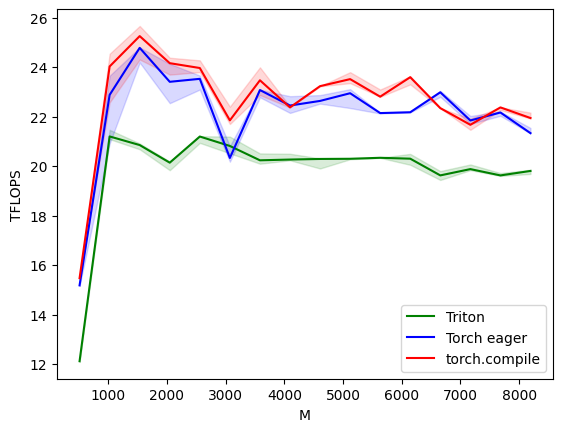

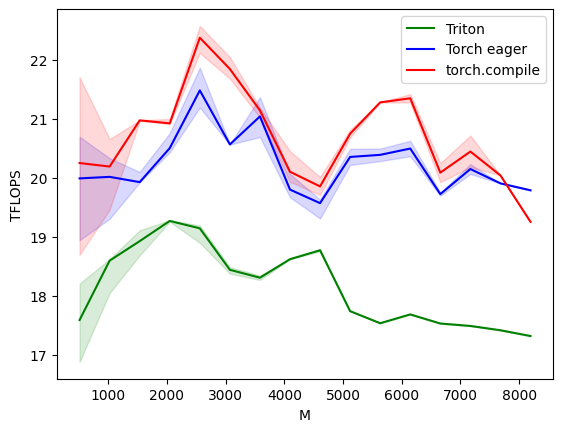

In [12]:
#@title run check and benchmark
ptxas = os.path.join(os.path.dirname(triton.__file__), "backends/nvidia/bin/ptxas")
os.environ["TRITON_PTXAS_PATH"] = ptxas
os.makedirs("results", exist_ok=True)

if not torch.cuda.is_available():
  raise RuntimeError("Get a GPU to run the code!")

N, K = 2048, 5504
for M in [512 * i for i in range(1, 17)]:
  check_triton_result(M, N, K)
# try non-multiples of 2
check_triton_result(670, 760, 123)

fwd_benchmark.run(save_path="results")
bwd_benchmark.run(save_path="results")